# Qwen-Image 2.1 Image Editing — Google Colab T4 (Safety-Aware Demo)

A ComfyUI workflow for experimenting with quantized Qwen-Image 2.1 image editing on a constrained NVIDIA T4 GPU.

## Pipeline

- Qwen-Image 2.1 GGUF diffusion model (configured file: `qwen-image-2.1-UC-Q8_0.gguf`).
- Qwen3-VL 8B INT8 text encoder.
- Qwen Image 2.1 BF16 VAE.
- ComfyUI Qwen-Image conditioning and image upload.
- No third-party LoRA is downloaded or applied in the public version.
- Prompt screening, reference-image screening, and output-image moderation.
- Explicit cleanup between conditioning, sampling, and decoding stages to reduce memory pressure.

## Reproducibility notes

- The configured GGUF repository is third-party and uses an uncensored-labelled model variant; the public notebook applies prompt screening and image moderation as defense-in-depth. These checks are best-effort, not a guarantee.
- The configured GGUF file is **Q8_0**, not Q8_0. Labels and settings below use Q8_0 consistently.
- Run cells in order in a fresh Colab GPU runtime. The setup cell handles ComfyUI checkout, so a separate destructive repair cell is not required.
- Model weights, uploaded reference images, and generated images are not included in this notebook.
- This cleaned copy has outputs cleared to remove personal prompts, uploaded images, and stale failure logs. Rerun in Colab to validate current compatibility.


In [1]:
# @title 1. Prepare Environment + Download Qwen-Image 2.1 {"single-column":true}

import os
import sys
import gc
import shutil
import subprocess
import hashlib
import requests
import json
from pathlib import Path


# ============================================================
# QWEN-IMAGE 2.1 — FINAL T4 SETUP
# ============================================================

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

%cd /content

# ============================================================
# BASIC PATHS
# ============================================================

COMFY_ROOT = Path(
    "/content/ComfyUI"
)

COMFY_INPUT = (
    COMFY_ROOT / "input"
)

GGUF_ROOT = (
    COMFY_ROOT
    / "custom_nodes"
    / "ComfyUI-GGUF"
)


# ============================================================
# COMFYUI VERSION
# ============================================================

COMFY_TAG = "v0.37.0"


# ============================================================
# OFFICIAL QWEN FILES
# ============================================================

QWEN_REPO = (
    "Comfy-Org/Qwen-Image-2.1"
)

TEXT_ENCODER_FILE = (
    "qwen3vl_8b_int8_convrot.safetensors"
)

VAE_FILE = (
    "qwen_image_2.1_vae_bf16.safetensors"
)


TEXT_ENCODER_PATH = (
    COMFY_ROOT
    / "models"
    / "text_encoders"
    / TEXT_ENCODER_FILE
)

VAE_PATH = (
    COMFY_ROOT
    / "models"
    / "vae"
    / VAE_FILE
)


# ============================================================
# CURRENT QWEN-IMAGE 2.1 GGUF
# ============================================================

GGUF_REPO = (
    "abenzerps/Qwen-Image-2.1-Uncensored-GGUF"
)

GGUF_FILE = (
    "qwen-image-2.1-UC-Q8_0.gguf"
)

GGUF_PATH = (
    COMFY_ROOT
    / "models"
    / "diffusion_models"
    / GGUF_FILE
)


# Public version intentionally does not download or apply third-party LoRAs.
LORA_DIR = (
    COMFY_ROOT
    / "models"
    / "loras"
)


# ------------------------------------------------------------
# Create directories
# ------------------------------------------------------------

for directory in [
    COMFY_INPUT,
    TEXT_ENCODER_PATH.parent,
    VAE_PATH.parent,
    GGUF_PATH.parent,
    LORA_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# HEADER
# ============================================================

print("=" * 72)
print(
    "QWEN-IMAGE 2.1 — T4 INITIALIZATION"
)
print("=" * 72)


# ============================================================
# 1. GPU CHECK
# ============================================================

print(
    "\n[1/7] Checking GPU..."
)

import torch

if not torch.cuda.is_available():

    raise RuntimeError(
        "CUDA GPU was not detected."
    )

print(
    "Python :",
    sys.version.split()[0]
)

print(
    "Torch  :",
    torch.__version__
)

print(
    "CUDA   :",
    torch.version.cuda
)

print(
    "GPU    :",
    torch.cuda.get_device_name(0)
)

print(
    "VRAM   :",
    round(
        torch.cuda.get_device_properties(0)
        .total_memory
        / 1024**3,
        2
    ),
    "GiB"
)


# ============================================================
# 2. PREPARE COMFYUI
# ============================================================

print(
    "\n[2/7] Preparing ComfyUI..."
)


# ------------------------------------------------------------
# Helper: clone with visible error output
# ------------------------------------------------------------

def clone_comfyui():

    clone_urls = [

        # Current canonical organization.
        "https://github.com/Comfy-Org/ComfyUI.git",

        # Fallback for environments where the redirect/repo
        # resolution behaves differently.
        "https://github.com/comfyanonymous/ComfyUI.git",

    ]

    for repo_url in clone_urls:

        # Remove a partial failed checkout.
        if COMFY_ROOT.exists():

            shutil.rmtree(
                COMFY_ROOT,
                ignore_errors=True
            )

        print(
            "\nTrying:"
        )

        print(
            repo_url
        )

        result = subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                COMFY_TAG,
                repo_url,
                str(COMFY_ROOT),
            ],
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            check=False,
        )

        print(
            result.stdout
        )

        if result.returncode == 0:

            print(
                "✓ ComfyUI clone succeeded."
            )

            return

        print(
            f"⚠ Clone failed with exit code "
            f"{result.returncode}."
        )


    raise RuntimeError(
        "\nCould not clone ComfyUI "
        f"{COMFY_TAG} from either repository."
    )


# ------------------------------------------------------------
# Existing working installation?
# ------------------------------------------------------------

if not (
    COMFY_ROOT.exists()
    and
    (COMFY_ROOT / "nodes.py").exists()
    and
    (COMFY_ROOT / "requirements.txt").exists()
):

    print(
        "ComfyUI is missing or incomplete."
    )

    clone_comfyui()

else:

    print(
        "✓ Existing ComfyUI installation found."
    )


# ------------------------------------------------------------
# Verify required files
# ------------------------------------------------------------

if not (
    COMFY_ROOT / "nodes.py"
).exists():

    raise RuntimeError(
        "ComfyUI nodes.py is missing."
    )

if not (
    COMFY_ROOT / "requirements.txt"
).exists():

    raise RuntimeError(
        "ComfyUI requirements.txt is missing."
    )


# ------------------------------------------------------------
# Ensure desired tag where possible.
# ------------------------------------------------------------

checkout = subprocess.run(
    [
        "git",
        "-C",
        str(COMFY_ROOT),
        "checkout",
        "--force",
        COMFY_TAG,
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    check=False,
)

if checkout.returncode != 0:

    print(
        "⚠ Could not explicitly checkout "
        f"{COMFY_TAG}."
    )

    print(
        checkout.stdout
    )

else:

    print(
        f"✓ ComfyUI checked out at {COMFY_TAG}."
    )


# ============================================================
# 3. INSTALL COMFYUI DEPENDENCIES
# ============================================================

print(
    "\n[3/7] Installing ComfyUI dependencies..."
)


# ------------------------------------------------------------
# Preserve the installed Torch build.
# ------------------------------------------------------------

constraints_file = Path(
    "/content/comfy_colab_constraints.txt"
)

constraints_file.write_text(
    f"torch=={torch.__version__}\n"
)


subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-r",
        str(
            COMFY_ROOT
            / "requirements.txt"
        ),
        "-c",
        str(constraints_file),
    ],
    check=True,
)


# Additional packages required by this notebook.
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "requests",
        "nest_asyncio",
        "safetensors",
    ],
    check=True,
)


print(
    "✓ ComfyUI dependencies installed."
)


# ============================================================
# 4. COMFYUI-GGUF
# ============================================================

print(
    "\n[4/7] Preparing current ComfyUI-GGUF..."
)


if GGUF_ROOT.exists():

    print(
        "Existing ComfyUI-GGUF found."
    )

    pull = subprocess.run(
        [
            "git",
            "-C",
            str(GGUF_ROOT),
            "pull",
            "--ff-only",
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        check=False,
    )

    if pull.returncode == 0:

        print(
            "✓ ComfyUI-GGUF updated."
        )

    else:

        print(
            "⚠ Existing GGUF repository "
            "could not be fast-forwarded."
        )

        print(
            pull.stdout[-3000:]
        )

else:

    gguf_clone = subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/city96/ComfyUI-GGUF.git",
            str(GGUF_ROOT),
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        check=False,
    )

    print(
        gguf_clone.stdout
    )

    if gguf_clone.returncode != 0:

        raise RuntimeError(
            "ComfyUI-GGUF clone failed."
        )

    print(
        "✓ ComfyUI-GGUF cloned."
    )


# ------------------------------------------------------------
# GGUF Python dependency
# ------------------------------------------------------------

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "gguf",
    ],
    check=True,
)


if (
    GGUF_ROOT / "requirements.txt"
).exists():

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "-r",
            str(
                GGUF_ROOT
                / "requirements.txt"
            ),
        ],
        check=True,
    )


print(
    "✓ Current GGUF support ready."
)

# ============================================================
# 4A. PATCH + VERIFY QWEN-IMAGE 2.1 GGUF ARCHITECTURE
#
# This MUST happen before Block 3.  It used to live below
# Block 3, which meant a fresh run could reach model loading
# before the loader knew about qwen_image21.
# ============================================================

GGUF_LOADER = GGUF_ROOT / "loader.py"

if not GGUF_LOADER.exists():
    raise FileNotFoundError(
        f"ComfyUI-GGUF loader.py not found:\n{GGUF_LOADER}"
    )

loader_text = GGUF_LOADER.read_text(encoding="utf-8")

old_arch_line = (
    'IMG_ARCH_LIST = {"flux", "sd1", "sdxl", "sd3", '
    '"aura", "hidream", "cosmos", "ltxv", "hyvid", '
    '"wan", "lumina2", "qwen_image"}'
)

new_arch_line = (
    'IMG_ARCH_LIST = {"flux", "sd1", "sdxl", "sd3", '
    '"aura", "hidream", "cosmos", "ltxv", "hyvid", '
    '"wan", "lumina2", "qwen_image", "qwen_image21"}'
)

if old_arch_line in loader_text:
    backup = GGUF_LOADER.with_suffix(".py.backup")
    if not backup.exists():
        shutil.copy2(GGUF_LOADER, backup)
    loader_text = loader_text.replace(old_arch_line, new_arch_line, 1)
    GGUF_LOADER.write_text(loader_text, encoding="utf-8")
    print("✓ Added qwen_image21 to ComfyUI-GGUF architecture list.")
elif "qwen_image21" in loader_text.split("TXT_ARCH_LIST")[0]:
    print("✓ qwen_image21 architecture support already present.")
else:
    raise RuntimeError(
        "Could not patch ComfyUI-GGUF: expected IMG_ARCH_LIST was not found.\n"
        f"Loader: {GGUF_LOADER}"
    )

# Verify the patch before importing/loading the custom node.
patched_text = GGUF_LOADER.read_text(encoding="utf-8")
if "qwen_image21" not in patched_text.split("TXT_ARCH_LIST")[0]:
    raise RuntimeError("qwen_image21 patch verification failed.")

print("✓ qwen_image21 loader patch verified.")



# ============================================================
# 5. DOWNLOAD QWEN MODELS
# ============================================================

print(
    "\n[5/7] Preparing Qwen-Image 2.1 models..."
)

from huggingface_hub import hf_hub_download


def hf_copy(
    repo_id,
    filename,
    destination,
):

    destination = Path(
        destination
    )

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )


    if (
        destination.exists()
        and
        destination.stat().st_size > 0
    ):

        print(
            "Already present:",
            destination.name
        )

        return


    print(
        "\nDownloading:",
        filename
    )


    cached_file = hf_hub_download(
        repo_id=repo_id,
        filename=filename,
    )


    shutil.copy2(
        cached_file,
        destination
    )


    print(
        "✓ Stored:",
        destination
    )


# ------------------------------------------------------------
# Official Qwen3-VL INT8 encoder
# ------------------------------------------------------------

hf_copy(
    QWEN_REPO,
    "text_encoders/"
    + TEXT_ENCODER_FILE,
    TEXT_ENCODER_PATH,
)


# ------------------------------------------------------------
# Official Qwen Image 2.1 VAE
# ------------------------------------------------------------

hf_copy(
    QWEN_REPO,
    "vae/"
    + VAE_FILE,
    VAE_PATH,
)


# ------------------------------------------------------------
# Current uncensored Q8_0 GGUF
# ------------------------------------------------------------

hf_copy(
    GGUF_REPO,
    GGUF_FILE,
    GGUF_PATH,
)


print("\n[6/7] Third-party LoRA download disabled in the public safety-focused notebook.")


# ============================================================
# LOAD COMFYUI-GGUF THROUGH COMFYUI ITSELF
# ============================================================

print(
    "\nLoading ComfyUI node registry..."
)

os.chdir(
    COMFY_ROOT
)

if str(COMFY_ROOT) not in sys.path:

    sys.path.insert(
        0,
        str(COMFY_ROOT)
    )


import nest_asyncio

nest_asyncio.apply()


from nodes import (
    NODE_CLASS_MAPPINGS,
    load_custom_node,
)


from comfy_extras.nodes_qwen import (
    TextEncodeQwenImage21,
)


# ------------------------------------------------------------
# Load custom node using ComfyUI's own loader.
# This avoids the old:
#
#   custom_nodes.ComfyUI_GGUF
#
# Python-package problem.
# ------------------------------------------------------------

import asyncio


async def load_gguf_node():

    return await load_custom_node(
        str(GGUF_ROOT),
        ignore=set(),
        module_parent="custom_nodes",
    )


loop = asyncio.get_event_loop()

gguf_loaded = (
    loop.run_until_complete(
        load_gguf_node()
    )
)


if not gguf_loaded:

    raise RuntimeError(
        "ComfyUI-GGUF failed to load."
    )


if (
    "UnetLoaderGGUF"
    not in NODE_CLASS_MAPPINGS
):

    raise RuntimeError(
        "UnetLoaderGGUF was not registered "
        "by ComfyUI-GGUF."
    )


print(
    "✓ Native ComfyUI loaded."
)

print(
    "✓ Native Qwen-Image-2.1 node loaded."
)

print(
    "✓ Current ComfyUI-GGUF loaded."
)

print(
    "✓ UnetLoaderGGUF registered."
)


# ============================================================
# REGISTER GGUF PATH
# ============================================================

import folder_paths


gguf_entry = (
    folder_paths.folder_names_and_paths
    .get(
        "unet_gguf"
    )
)


if gguf_entry is None:

    folder_paths.folder_names_and_paths[
        "unet_gguf"
    ] = (
        [
            str(
                GGUF_PATH.parent
                .resolve()
            )
        ],
        {
            ".gguf"
        }
    )

else:

    existing_paths, extensions = (
        gguf_entry
    )

    target_dir = str(
        GGUF_PATH.parent.resolve()
    )

    normalized_paths = [
        str(
            Path(p).resolve()
        )
        for p in existing_paths
    ]

    if (
        target_dir
        not in normalized_paths
    ):

        existing_paths.append(
            target_dir
        )

    extensions.add(
        ".gguf"
    )


# ------------------------------------------------------------
# Verify ComfyUI visibility.
# ------------------------------------------------------------

visible_gguf = (
    folder_paths.get_filename_list(
        "unet_gguf"
    )
)


print(
    "\nGGUF files visible to ComfyUI:"
)

for filename in visible_gguf:

    print(
        "  ",
        filename
    )


if (
    GGUF_FILE
    not in visible_gguf
):

    raise RuntimeError(
        "\nQwen UC GGUF exists on disk but "
        "is not visible to UnetLoaderGGUF."
    )


print(
    "\n✓ Qwen UC Q8_0 GGUF is visible."
)


# ============================================================
# FINAL VRAM CHECK
# ============================================================

gc.collect()

torch.cuda.empty_cache()

try:
    torch.cuda.ipc_collect()
except Exception:
    pass


free, total = (
    torch.cuda.mem_get_info()
)


# ============================================================
# FINAL STATUS
# ============================================================

print(
    "\n" + "=" * 72
)

print(
    "BLOCK 1 READY"
)

print(
    "=" * 72
)

print(
    "Qwen UC GGUF :",
    GGUF_PATH
)

print(
    "Qwen3-VL     :",
    TEXT_ENCODER_PATH
)

print(
    "Qwen VAE     :",
    VAE_PATH
)

print("Third-party LoRA: disabled in public version\n")

print(
    f"Free VRAM    : "
    f"{free / 1024**3:.2f} GiB"
)

print(
    "\n✓ READY FOR BLOCK 2"
)

print(
    "=" * 72
)

/content
QWEN-IMAGE 2.1 — T4 INITIALIZATION

[1/7] Checking GPU...
Python : 3.13.15
Torch  : 2.11.0+cu130
CUDA   : 13.0
GPU    : Tesla T4
VRAM   : 14.56 GiB

[2/7] Preparing ComfyUI...
ComfyUI is missing or incomplete.

Trying:
https://github.com/Comfy-Org/ComfyUI.git
Cloning into '/content/ComfyUI'...
Note: switching to '73c9bad4d21e7addbe1d13bc92eee0f1431b017d'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false


✓ ComfyUI clone succeeded.
✓ ComfyUI checked out at v0.37.0.

[3/7] Installing ComfyUI dependencies...
✓ ComfyUI de

text_encoders/qwen3vl_8b_int8_convrot.sa(…): reconstructing file:   0%|          |  0.00B / 9.35GB            

text_encoders/qwen3vl_8b_int8_convrot.sa(…): downloading bytes:           |  0.00B            

✓ Stored: /content/ComfyUI/models/text_encoders/qwen3vl_8b_int8_convrot.safetensors

Downloading: vae/qwen_image_2.1_vae_bf16.safetensors


vae/qwen_image_2.1_vae_bf16.safetensors: reconstructing file:   0%|          |  0.00B /  676MB            

vae/qwen_image_2.1_vae_bf16.safetensors: downloading bytes:           |  0.00B            

✓ Stored: /content/ComfyUI/models/vae/qwen_image_2.1_vae_bf16.safetensors

Downloading: qwen-image-2.1-UC-Q8_0.gguf


qwen-image-2.1-UC-Q8_0.gguf: reconstructing file:   0%|          |  0.00B / 7.59GB            

qwen-image-2.1-UC-Q8_0.gguf: downloading bytes:           |  0.00B            

✓ Stored: /content/ComfyUI/models/diffusion_models/qwen-image-2.1-UC-Q8_0.gguf

[6/7] Third-party LoRA download disabled in the public safety-focused notebook.

Loading ComfyUI node registry...
✓ Native ComfyUI loaded.
✓ Native Qwen-Image-2.1 node loaded.
✓ Current ComfyUI-GGUF loaded.
✓ UnetLoaderGGUF registered.

GGUF files visible to ComfyUI:
   qwen-image-2.1-UC-Q8_0.gguf

✓ Qwen UC Q8_0 GGUF is visible.

BLOCK 1 READY
Qwen UC GGUF : /content/ComfyUI/models/diffusion_models/qwen-image-2.1-UC-Q8_0.gguf
Qwen3-VL     : /content/ComfyUI/models/text_encoders/qwen3vl_8b_int8_convrot.safetensors
Qwen VAE     : /content/ComfyUI/models/vae/qwen_image_2.1_vae_bf16.safetensors
Third-party LoRA: disabled in public version

Free VRAM    : 14.46 GiB

✓ READY FOR BLOCK 2


In [ ]:

# @title 2. 📸 Generation Mode & Optional Reference Upload {"single-column":true}

from google.colab import files
from pathlib import Path
import shutil

COMFY_INPUT = Path("/content/ComfyUI/input")
COMFY_INPUT.mkdir(parents=True, exist_ok=True)

VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

# ------------------------------------------------------------
# MODE SELECTION
# Define this control in Section 1 / User Controls.
# ------------------------------------------------------------

if "use_reference_images" not in globals():
    use_reference_images = True

REFERENCE_FILES = []

print("=" * 72)
print("QWEN-IMAGE 2.1 — GENERATION MODE")
print("=" * 72)

if use_reference_images:
    print("Mode: IMAGE EDITING")
    print("Upload 1–3 reference images.")
    print("For pose transfer:")
    print("  image_1 = person / appearance reference")
    print("  image_2 = desired pose reference")

    uploaded = files.upload()

    for filename in uploaded.keys():
        source = Path(filename)

        if source.suffix.lower() not in VALID_EXTENSIONS:
            print(f"Skipping unsupported file: {filename}")
            continue

        # Avoid overwriting a different file with the same name.
        destination = COMFY_INPUT / source.name
        if destination.exists():
            destination = COMFY_INPUT / (
                f"{source.stem}_{len(REFERENCE_FILES) + 1}{source.suffix}"
            )

        shutil.copy2(source, destination)
        REFERENCE_FILES.append(destination.name)

        if len(REFERENCE_FILES) >= 3:
            print("Reference limit reached: using the first 3 valid images.")
            break

    if not REFERENCE_FILES:
        raise RuntimeError(
            "Image-editing mode is enabled, but no valid reference images "
            "were uploaded. Upload at least one image or disable "
            "'use_reference_images' in Section 1."
        )

    print("\nRegistered reference images:")
    for i, filename in enumerate(REFERENCE_FILES, 1):
        print(f"  image_{i}: {filename}")
        print(f"           {COMFY_INPUT / filename}")

    print("\n✓ REFERENCE_FILES is ready.")

else:
    print("Mode: TEXT-TO-IMAGE")
    print("No reference images are required.")
    REFERENCE_FILES = []
    print("✓ REFERENCE_FILES is an empty list.")


In [2]:
# @title GPU-wide VRAM sampling helper

# LowVRAM Lab: GPU-wide VRAM sampling helper
import subprocess
import threading
import time

class GPUMemoryMonitor:
    """Sample total GPU memory usage with nvidia-smi while a workload runs."""

    def __init__(self, interval=0.5):
        self.interval = interval
        self.baseline_mib = None
        self.peak_mib = None
        self.samples = []
        self._stop_event = threading.Event()
        self._thread = None

    def _read_mib(self):
        try:
            result = subprocess.run(
                [
                    "nvidia-smi",
                    "--query-gpu=memory.used",
                    "--format=csv,noheader,nounits",
                ],
                capture_output=True,
                text=True,
                timeout=3,
                check=True,
            )
            values = [
                int(line.strip())
                for line in result.stdout.splitlines()
                if line.strip()
            ]
            return values[0] if values else None
        except Exception:
            return None

    def _sample_loop(self):
        while not self._stop_event.is_set():
            value = self._read_mib()
            if value is not None:
                if self.baseline_mib is None:
                    self.baseline_mib = value
                self.samples.append(value)
                self.peak_mib = (
                    value if self.peak_mib is None
                    else max(self.peak_mib, value)
                )
            self._stop_event.wait(self.interval)

    def start(self):
        self._stop_event.clear()
        self.samples = []
        self.baseline_mib = None
        self.peak_mib = None
        self._thread = threading.Thread(
            target=self._sample_loop, daemon=True
        )
        self._thread.start()
        time.sleep(0.2)
        return self

    def stop(self):
        self._stop_event.set()
        if self._thread is not None:
            self._thread.join(timeout=3)

        print("\n--- GPU memory measurement ---")
        if self.baseline_mib is None or self.peak_mib is None:
            print("VRAM measurement unavailable; check nvidia-smi.")
        else:
            print(f"Baseline GPU memory: {self.baseline_mib / 1024:.2f} GiB")
            print(f"Sampled peak GPU memory: {self.peak_mib / 1024:.2f} GiB")
            print(
                "Peak increase over first sample: "
                f"{(self.peak_mib - self.baseline_mib) / 1024:.2f} GiB"
            )
            print(f"Sampling interval: {self.interval:.1f} seconds")
            print(f"Number of samples: {len(self.samples)}")
            print("Note: GPU-wide usage; other processes may contribute.")


Safety prompt check passed for text-to-image prompt (keyword-based; not a guarantee).
Safety prompt check passed for text-to-image prompt (keyword-based; not a guarantee).
Text-to-image mode: skipping reference-image moderation.

MODEL FILE CHECK
✓ Q8_0 GGUF: 7.070 GiB
✓ Qwen3-VL INT8: 8.709 GiB
✓ Qwen VAE: 0.629 GiB
Text-to-image mode: no reference images selected.

Text-to-image mode: skipping reference sizing. The encoder will create the empty latent from the resolution setting.

Importing ComfyUI nodes...
✓ ComfyUI nodes ready.
Skipping reference-image loading.

Loading Qwen VAE...
✓ VAE loaded.
[RAM after VAE] 3.82 GiB
[VRAM after VAE] free=14.46 GiB | allocated=0.00 GiB | reserved=0.00 GiB

Loading Qwen3-VL 8B INT8...
✓ Qwen3-VL loaded.
[RAM after Qwen3-VL] 3.96 GiB
[VRAM after Qwen3-VL] free=14.46 GiB | allocated=0.00 GiB | reserved=0.00 GiB

Encoding prompt + empty reference set...
Qwen conditioning complete.
[RAM after conditioning] 4.23 GiB
[VRAM after conditioning] free=5.44

  0%|          | 0/30 [00:00<?, ?it/s]


✓ Sampling complete.
[VRAM after sampling] free=6.17 GiB | allocated=7.08 GiB | reserved=8.27 GiB
[RAM after sampling] 6.19 GiB

Releasing diffusion model...
[RAM after GGUF release] 4.19 GiB
[VRAM after GGUF release] free=14.39 GiB | allocated=0.01 GiB | reserved=0.04 GiB
[RAM after conditioning release] 4.19 GiB

Loading Qwen VAE for decode...
✓ VAE ready.
[VRAM decode VAE] free=14.39 GiB | allocated=0.01 GiB | reserved=0.04 GiB
[RAM decode VAE] 4.30 GiB

Decoding...


✓ Decode complete.


config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Safety scan — Qwen-Image generated output: NSFW score=0.000; threshold=0.85

✓ Output saved and passed the configured safety scan:
/content/qwen_image_t2i_output.png


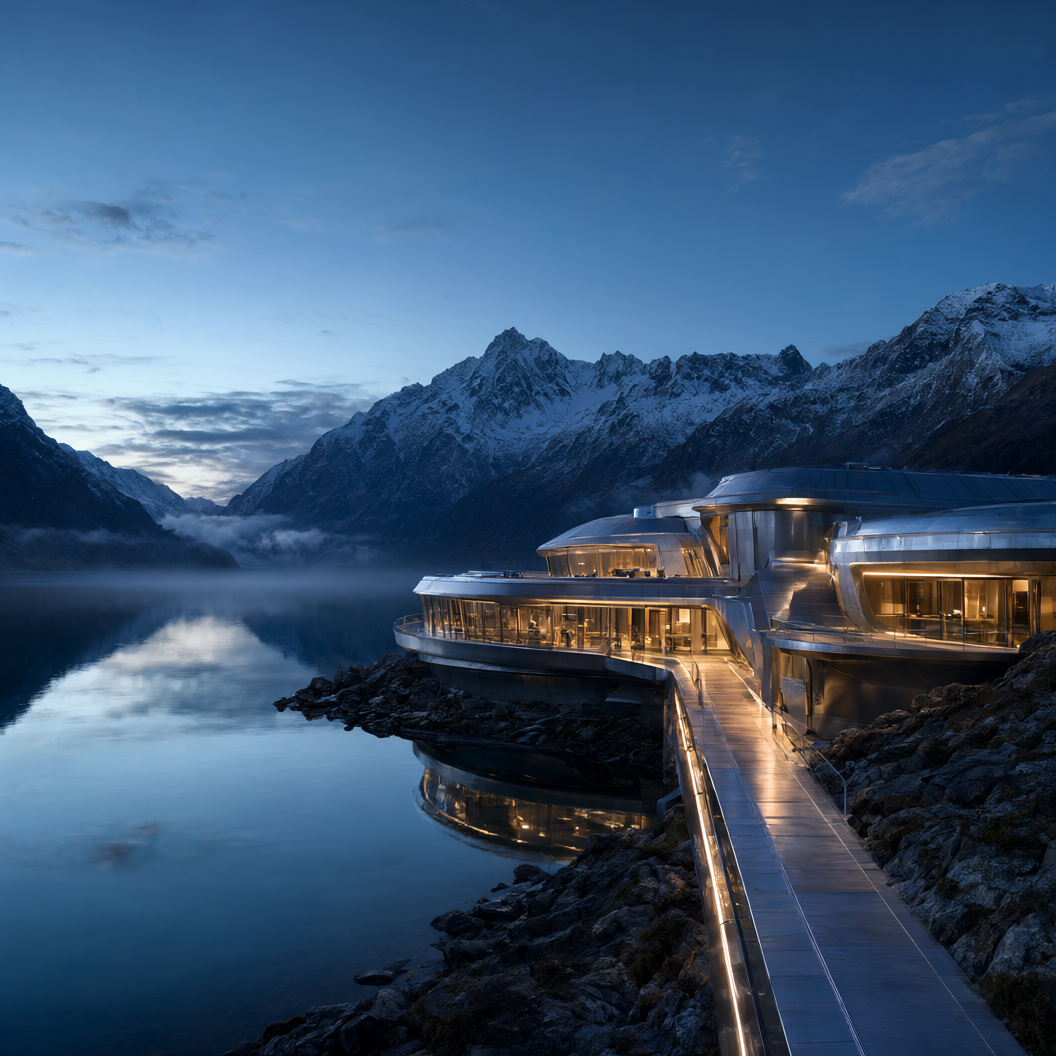


Performing final cleanup...
[RAM FINAL] 4.79 GiB
[VRAM FINAL] free=14.39 GiB | allocated=0.01 GiB | reserved=0.04 GiB

BLOCK 3 COMPLETE
[RAM FAIL-SAFE FINAL] 4.79 GiB
[VRAM FAIL-SAFE FINAL] free=14.39 GiB | allocated=0.01 GiB | reserved=0.04 GiB


In [15]:
# @title 3. Qwen-Image 2.1 Q8_0 — Safety-Aware T4 Runner {"single-column":true}

# ============================================================
# QWEN-IMAGE 2.1 Q8_0
# STABLE REPEATED-RUN T4 BLOCK
#
# Designed for:
#   - Google Colab T4
#   - ~12 GB system RAM
#   - ~14.5 GiB VRAM
#
# MEMORY STRATEGY:
#
#   Stage A:
#       Reference image
#       Qwen3-VL
#       VAE
#           ↓
#       conditioning
#
#   HARD RELEASE
#
#   Stage B:
#       Q8_0 GGUF
#       sampling
#
#   HARD RELEASE
#
#   Stage C:
#       VAE
#       decode
#
#   HARD RELEASE
#
# IMPORTANT:
#   Do NOT run another Block 3 until this block says
#   "BLOCK 3 COMPLETE".
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import sys
import gc
import math
import random
import logging
import psutil

from pathlib import Path

import numpy as np
import torch

from PIL import Image, ImageOps
from IPython.display import display


# ============================================================
# 1. RAM / VRAM MONITORING
# ============================================================

_process = psutil.Process(os.getpid())


def print_ram(label=""):

    ram = (
        _process.memory_info().rss
        / 1024**3
    )

    print(
        f"[RAM {label}] "
        f"{ram:.2f} GiB"
    )

    return ram


def print_vram(label=""):

    if not torch.cuda.is_available():

        print(
            f"[VRAM {label}] CUDA unavailable"
        )

        return

    free, total = (
        torch.cuda.mem_get_info()
    )

    allocated = (
        torch.cuda.memory_allocated()
    )

    reserved = (
        torch.cuda.memory_reserved()
    )

    print(
        f"[VRAM {label}] "
        f"free={free/1024**3:.2f} GiB | "
        f"allocated={allocated/1024**3:.2f} GiB | "
        f"reserved={reserved/1024**3:.2f} GiB"
    )


# ============================================================
# 2. MEMORY CLEANUP
# ============================================================

def cleanup_memory():

    gc.collect()

    if torch.cuda.is_available():

        try:
            torch.cuda.empty_cache()
        except Exception:
            pass

        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass


def unload_comfy_models():

    try:

        import comfy.model_management as mm

        if hasattr(mm, "unload_all_models"):
            mm.unload_all_models()
        if hasattr(mm, "cleanup_models"):
            mm.cleanup_models()

    except Exception as e:

        print(
            "ComfyUI unload warning:",
            repr(e)
        )


def hard_cleanup():

    unload_comfy_models()

    cleanup_memory()



# ============================================================
# 4. USER CONTROLS
# ============================================================

use_reference_images = False  # @param {type:"boolean"}

positive_prompt = "A cinematic, photorealistic wide shot of a futuristic research station built beside a vast alpine lake at blue hour. The station has elegant brushed titanium architecture, warm amber lights glowing through large glass windows, and a narrow illuminated walkway leading toward the water. Snow-covered mountain peaks rise in the background, reflected almost perfectly in the calm lake. A few delicate clouds drift across the deep blue evening sky, with faint mist hovering above the water. Sophisticated science-fiction production design, physically realistic materials, natural atmospheric perspective, subtle volumetric lighting, detailed reflections, balanced exposure, restrained teal-and-amber color grading, professional cinematography, realistic 35mm lens, carefully composed foreground and background, no people, no text, no logos, no watermark. The scene should look like a frame from a high-budget science-fiction film." # @param {type:"string"}

negative_prompt = "" # @param {type:"string"}


# IMPORTANT:
# Colab @param dropdowns can return strings.
# We explicitly convert them below.

reference_resolution = "768"  # @param [512,640,768,896,992,1056]

reference_count = "1"  # @param [1,2,3,4]

seed = 0  # @param {type:"integer"}

steps = 30  # @param {type:"slider", "min":10, "max":40, "step":1}

cfg = 1.0  # @param {type:"slider", "min":0.5, "max":1.5, "step":0.05}

denoise = 1.0  # @param {type:"slider", "min":0.0, "max":1.0, "step":0.01}

sampler_name = "euler"  # @param ["euler"]

scheduler = "simple"  # @param ["simple"]

output_path = (
    "/content/qwen_image_edit_output.png"
    if use_reference_images
    else "/content/qwen_image_t2i_output.png"
)
# Public-demo safety gate: prompt screening plus output moderation.
# This is defense-in-depth, not a guarantee. Classifiers can miss content or flag benign images.
import re, shutil, time
from pathlib import Path
from PIL import Image

NSFW_SCORE_THRESHOLD = 0.85
SAFETY_MODEL_ID = "Falconsai/nsfw_image_detection"
_safety_classifier = None

_BLOCKED_PROMPT_PATTERNS = [
    r"\bnsfw\b", r"\b(nude|nudity|naked)\b", r"\b(porn|pornographic|erotic)\b",
    r"\b(genitals|penis|vagina|vulva|breasts?)\b", r"\b(masturbat\w*|orgasm|ejaculat\w*|intercourse)\b",
    r"\b(explicit sexual|sexual act|sexually explicit)\b",
]
_MINOR_SEXUAL_PATTERN = re.compile(
    r"\b(child|children|minor|underage|teen|teenager)\b.{0,80}\b(nude|nudity|naked|sexual|sex|explicit|porn)\b|"
    r"\b(nude|nudity|naked|sexual|sex|explicit|porn)\b.{0,80}\b(child|children|minor|underage|teen|teenager)\b",
    re.IGNORECASE,
)

def enforce_public_prompt_policy(prompt, label="prompt"):
    text = str(prompt or "")
    hits = [pattern for pattern in _BLOCKED_PROMPT_PATTERNS if re.search(pattern, text, re.IGNORECASE)]
    if hits or _MINOR_SEXUAL_PATTERN.search(text):
        raise ValueError(
            f"Safety gate blocked the {label}: it appears to request explicit sexual/nudity content. "
            "Use a non-explicit prompt for this public demonstration."
        )
    print(f"Safety prompt check passed for {label} (keyword-based; not a guarantee).")

def _get_safety_classifier():
    global _safety_classifier
    if _safety_classifier is None:
        try:
            from transformers import pipeline
        except Exception as exc:
            raise RuntimeError(
                "Output moderation requires Transformers. Install/repair it in the Colab runtime, "
                "then rerun this cell; the public workflow fails closed when moderation is unavailable."
            ) from exc
        # Keep the moderator on CPU so it does not compete with the diffusion model for T4 VRAM.
        _safety_classifier = pipeline(
            "image-classification", model=SAFETY_MODEL_ID, device=-1
        )
    return _safety_classifier

def moderate_pil_image(image, label="image"):
    classifier = _get_safety_classifier()
    predictions = classifier(image.convert("RGB"), top_k=None)
    scores = {str(item.get("label", "")).lower(): float(item.get("score", 0.0)) for item in predictions}
    nsfw_score = scores.get("nsfw", 0.0)
    print(f"Safety scan — {label}: NSFW score={nsfw_score:.3f}; threshold={NSFW_SCORE_THRESHOLD:.2f}")
    if nsfw_score >= NSFW_SCORE_THRESHOLD:
        raise ValueError(f"Safety scan blocked {label} (NSFW score {nsfw_score:.3f}).")
    return nsfw_score

def moderate_image_file(path, label="image"):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Safety scan input does not exist: {path}")
    with Image.open(path) as image:
        return moderate_pil_image(image, label=label)

def moderate_video_file(path, label="generated video", samples=12):
    import cv2
    path = Path(path)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video for safety scanning: {path}")
    try:
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0:
            raise RuntimeError("Video has no readable frames; refusing to mark it as screened.")
        count = min(int(samples), total)
        indices = sorted(set(round(i * (total - 1) / max(count - 1, 1)) for i in range(count)))
        scores = []
        for index in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, index)
            ok, frame = cap.read()
            if not ok:
                raise RuntimeError(f"Could not read frame {index}; refusing to mark video as screened.")
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            score = moderate_pil_image(Image.fromarray(rgb), label=f"{label}, frame {index}")
            scores.append(score)
        max_score = max(scores, default=0.0)
        print(f"Video safety scan completed: {len(scores)} sampled frames; maximum NSFW score={max_score:.3f}.")
        return max_score
    finally:
        cap.release()

def quarantine_file(path, reason="flagged"):
    path = Path(path)
    quarantine = Path("/content/safety_quarantine")
    quarantine.mkdir(parents=True, exist_ok=True)
    destination = quarantine / f"{path.stem}_{reason}_{int(time.time())}{path.suffix}"
    if path.exists():
        shutil.move(str(path), str(destination))
    print("Output was not displayed as an approved result. Quarantined at:", destination)
    return destination


# Check prompt before any large model is loaded.
enforce_public_prompt_policy(
    positive_prompt,
    label=(
        "image-edit prompt"
        if use_reference_images
        else "text-to-image prompt"
    ),
)
# ============================================================
# TRANSACTIONAL RUNNER
#
# The entire model-loading/generation pipeline lives inside a
# function so a failure cannot leave the large objects as
# persistent IPython globals.  The finally block also releases
# partially-created objects on ANY Python exception.
# ============================================================

def _clear_previous_qwen_state():
    """Remove large objects left by an earlier failed Block 3."""
    stale_names = [
        "model", "gguf_loader", "sampler",
        "clip", "clip_loader", "encoder", "conditioning",
        "positive", "negative", "latent", "vae", "vae_loader",
        "decoder", "decoded", "sampled", "reference_tensors",
        "image_loader", "result", "output_tensor", "output_array",
        "output_image", "selected_names", "actual_seed",
    ]
    for name in stale_names:
        obj = globals().pop(name, None)
        del obj
    gc.collect()
    hard_cleanup()


def _run_qwen21_generation():
    enforce_public_prompt_policy(
        positive_prompt,
        label=(
            "image-edit prompt"
            if use_reference_images
            else "text-to-image prompt"
        ),
    )

    if use_reference_images:
        if not REFERENCE_FILES:
            raise RuntimeError(
                "Reference-image mode is enabled, but no images were uploaded."
            )

        for index, filename in enumerate(REFERENCE_FILES, 1):
            moderate_image_file(
                Path("/content/ComfyUI/input") / filename,
                label=f"reference image {index}",
            )
    else:
        print("Text-to-image mode: skipping reference-image moderation.")

    _clear_previous_qwen_state()

    # Every model object created below is released in this finally block,
    # whether generation succeeds, raises, or is interrupted by Python.
    model = gguf_loader = sampler = None
    clip = clip_loader = encoder = conditioning = None
    positive = negative = latent = None
    vae = vae_loader = decoder = None
    decoded = sampled = reference_tensors = image_loader = None
    output_tensor = output_array = output_image = None
    selected_names = None
    capture = None

    try:
        # 5. NORMALIZE COLAB PARAMETERS
        # ============================================================

        try:

            reference_resolution = int(
                reference_resolution
            )

        except Exception:

            reference_resolution = 1056


        try:

            reference_count = int(
                reference_count
            )

        except Exception:

            reference_count = 1


        reference_resolution = max(
            256,
            reference_resolution
        )


        # ============================================================
        # 6. PATHS
        # ============================================================

        COMFY_ROOT = Path(
            "/content/ComfyUI"
        )

        COMFY_INPUT = (
            COMFY_ROOT / "input"
        )

        GGUF_FILE = (
            "qwen-image-2.1-UC-Q8_0.gguf"
        )

        TEXT_ENCODER_FILE = (
            "qwen3vl_8b_int8_convrot.safetensors"
        )

        VAE_FILE = (
            "qwen_image_2.1_vae_bf16.safetensors"
        )

        GGUF_PATH = (
            COMFY_ROOT
            / "models"
            / "diffusion_models"
            / GGUF_FILE
        )

        TEXT_ENCODER_PATH = (
            COMFY_ROOT
            / "models"
            / "text_encoders"
            / TEXT_ENCODER_FILE
        )

        VAE_PATH = (
            COMFY_ROOT
            / "models"
            / "vae"
            / VAE_FILE
        )


        # ============================================================
        # 8. VERIFY MODEL FILES
        # ============================================================

        print(
            "\n" + "=" * 72
        )

        print(
            "MODEL FILE CHECK"
        )

        print(
            "=" * 72
        )

        for label, path in [

            (
                "Q8_0 GGUF",
                GGUF_PATH
            ),

            (
                "Qwen3-VL INT8",
                TEXT_ENCODER_PATH
            ),

            (
                "Qwen VAE",
                VAE_PATH
            ),

        ]:

            if not path.exists():

                raise FileNotFoundError(
                    f"{label} not found:\n"
                    f"{path}\n\n"
                    "Run Block 1 first."
                )

            size_gb = (
                path.stat().st_size
                / 1024**3
            )

            print(
                f"✓ {label}: "
                f"{size_gb:.3f} GiB"
            )


        # ============================================================
        # 9. SELECT GENERATION MODE
        # ============================================================

        if use_reference_images:
            if not REFERENCE_FILES:
                raise RuntimeError(
                    "Reference-image mode is enabled, but no valid reference images were uploaded. "
                    "Run Block 2 and upload at least one image, or disable use_reference_images."
                )

            reference_count = max(1, min(int(reference_count), len(REFERENCE_FILES), 3))
            selected_names = list(REFERENCE_FILES[:reference_count])

            for i, name in enumerate(selected_names, 1):
                reference_path = COMFY_INPUT / name
                if not reference_path.is_file():
                    raise FileNotFoundError(
                        f"Reference image {i} is missing: {reference_path}"
                    )
        else:
            selected_names = []
            reference_tensors = {}
            print("Text-to-image mode: no reference images selected.")

        # ============================================================
        # 10. QWEN NATIVE SIZE PREVIEW
        # ============================================================

        def qwen_dimensions(width, height, resolution, multiple=32):
            if width <= 0 or height <= 0:
                raise ValueError("Image width and height must be positive.")

            if resolution <= 0:
                return (
                    max(multiple, round(width / multiple) * multiple),
                    max(multiple, round(height / multiple) * multiple),
                )

            ratio = width / height
            new_width = round(
                math.sqrt(resolution * resolution * ratio) / multiple
            ) * multiple
            new_height = round(
                math.sqrt(resolution * resolution / ratio) / multiple
            ) * multiple

            return (
                max(multiple, new_width),
                max(multiple, new_height),
            )

        if use_reference_images:
            print("\nNative Qwen reference sizing:")
            for i, name in enumerate(selected_names, 1):
                with Image.open(COMFY_INPUT / name) as img:
                    img = ImageOps.exif_transpose(img)
                    ow, oh = img.size

                nw, nh = qwen_dimensions(ow, oh, reference_resolution)
                print(
                    f"  image_{i}: {ow}x{oh} -> {nw}x{nh} "
                    f"({nw * nh:,} px)"
                )
        else:
            print(
                "\nText-to-image mode: skipping reference sizing. "
                "The encoder will create the empty latent from the resolution setting."
            )

        # 11. IMPORT COMFYUI NODES
        # ============================================================

        print(
            "\nImporting ComfyUI nodes..."
        )

        os.chdir(
            COMFY_ROOT
        )

        COMFY_ROOT_STR = str(
            COMFY_ROOT.resolve()
        )

        if COMFY_ROOT_STR not in sys.path:

            sys.path.insert(
                0,
                COMFY_ROOT_STR
            )


        from nodes import (
            CLIPLoader,
            VAELoader,
            KSampler,
            VAEDecode,
            LoraLoaderModelOnly,
            NODE_CLASS_MAPPINGS,
        )

        from comfy_extras.nodes_qwen import (
            TextEncodeQwenImage21
        )


        if (
            "UnetLoaderGGUF"
            not in NODE_CLASS_MAPPINGS
        ):

            raise RuntimeError(
                "UnetLoaderGGUF is not registered.\n"
                "Run Block 1 again."
            )


        UnetLoaderGGUF = (
            NODE_CLASS_MAPPINGS[
                "UnetLoaderGGUF"
            ]
        )


        print(
            "✓ ComfyUI nodes ready."
        )


        # ============================================================
        # 12. LOAD REFERENCE IMAGES ONLY WHEN ENABLED
        # ============================================================

        reference_tensors = {}

        if use_reference_images:
            print("\nLoading reference image(s)...")

            image_loader = NODE_CLASS_MAPPINGS["LoadImage"]()

            try:
                for i, name in enumerate(selected_names, 1):
                    result = image_loader.load_image(
                        str(COMFY_INPUT / name)
                    )
                    reference_tensors[f"image_{i}"] = result[0]
                    del result
            finally:
                del image_loader
                gc.collect()

            print(
                f"Reference tensors prepared: {len(reference_tensors)} image(s)."
            )
        else:
            print("Skipping reference-image loading.")

        # ============================================================
        # 13. LOAD VAE
        # ============================================================

        print(
            "\nLoading Qwen VAE..."
        )

        hard_cleanup()

        vae_loader = (
            VAELoader()
        )

        vae = (
            vae_loader.load_vae(
                VAE_FILE
            )[0]
        )

        print(
            "✓ VAE loaded."
        )

        print_ram(
            "after VAE"
        )

        print_vram(
            "after VAE"
        )


        # ============================================================
        # 14. LOAD QWEN3-VL
        # ============================================================

        print(
            "\nLoading Qwen3-VL 8B INT8..."
        )

        hard_cleanup()

        clip_loader = (
            CLIPLoader()
        )

        clip = (
            clip_loader.load_clip(
                TEXT_ENCODER_FILE,
                "qwen_image",
                "default"
            )[0]
        )

        print(
            "✓ Qwen3-VL loaded."
        )

        print_ram(
            "after Qwen3-VL"
        )

        print_vram(
            "after Qwen3-VL"
        )


        # ============================================================
        # 15. NATIVE QWEN CONDITIONING
        # ============================================================

        print(
            "\nEncoding prompt + "
            + ("reference images..." if use_reference_images else "empty reference set...")
        )

        encoder = TextEncodeQwenImage21()

        conditioning = encoder.execute(
            clip=clip,
            prompt=positive_prompt,
            negative_prompt=negative_prompt,
            vae=vae,
            resolution=int(reference_resolution),
            images=reference_tensors if use_reference_images else {},
        )

        positive = conditioning[0]
        negative = conditioning[1]
        latent = conditioning[2]

        del conditioning
        del encoder
        del reference_tensors

        gc.collect()

        print("Qwen conditioning complete.")
        print_ram("after conditioning")
        print_vram("after conditioning")

        # ============================================================
        # 16. RELEASE QWEN3-VL COMPLETELY
        # ============================================================

        print(
            "\nReleasing Qwen3-VL..."
        )

        del clip
        del clip_loader

        gc.collect()

        unload_comfy_models()

        cleanup_memory()

        print_ram(
            "after Qwen3-VL release"
        )

        print_vram(
            "after Qwen3-VL release"
        )


        # ============================================================
        # 17. RELEASE FIRST-STAGE VAE
        # ============================================================

        print(
            "\nReleasing conditioning VAE..."
        )

        del vae
        del vae_loader

        gc.collect()

        unload_comfy_models()

        cleanup_memory()

        print_ram(
            "before GGUF"
        )

        print_vram(
            "before GGUF"
        )


        # ============================================================
        # 18. SAFETY CHECK
        #
        # The Q4 GGUF itself is ~4.3 GiB.
        # If system RAM is already dangerously high,
        # do NOT attempt another model load.
        # ============================================================

        current_ram = (
            _process.memory_info().rss
            / 1024**3
        )

        if current_ram > 8.5:

            raise RuntimeError(
                "\nCPU RAM is already too high before "
                "loading the Q4 GGUF.\n\n"
                f"Current RAM: {current_ram:.2f} GiB\n\n"
                "The Qwen3-VL stage was not completely "
                "released by the current runtime.\n"
                "Restart the Colab runtime once and run "
                "Block 1 → Block 2 → Block 3."
            )


        # ============================================================
        # 19. LOAD Q8_0 GGUF
        # ============================================================

        print(
            "\nLoading Qwen-Image 2.1 "
            "UC Q8_0 GGUF..."
        )

        gguf_loader = (
            UnetLoaderGGUF()
        )

        model = (
            gguf_loader.load_unet(
                GGUF_FILE
            )[0]
        )

        print(
            "✓ Q8_0 GGUF loaded."
        )

        print(
            "Model class:",
            type(
                model.model
            ).__name__
        )

        print_ram(
            "after GGUF"
        )

        print_vram(
            "after GGUF"
        )


        print("\nThird-party LoRA: disabled in public version.")


        # ============================================================
        # 21. SEED
        # ============================================================

        if seed == 0:

            actual_seed = (
                random.randint(
                    0,
                    2**32 - 1
                )
            )

        else:

            actual_seed = int(
                seed
            )


        print(
            "\nSeed:",
            actual_seed
        )


        # ============================================================
        # 22. SAMPLING
        # ============================================================

        print(
            "\n" + "=" * 72
        )

        print(
            "SAMPLING"
        )

        print(
            "=" * 72
        )

        print(
            "Steps     :",
            steps
        )

        print(
            "CFG       :",
            cfg
        )

        print(
            "Sampler   :",
            sampler_name
        )

        print(
            "Scheduler :",
            scheduler
        )

        print(
            "Denoise   :",
            denoise
        )

        print("LoRA      : OFF (public safety-focused configuration)\n")

        print_vram(
            "before sampling"
        )

        print_ram(
            "before sampling"
        )


        sampler = (
            KSampler()
        )

        sampled = (
            sampler.sample(
                model=model,
                seed=actual_seed,
                steps=steps,
                cfg=cfg,
                sampler_name=sampler_name,
                scheduler=scheduler,
                positive=positive,
                negative=negative,
                latent_image=latent,
                denoise=denoise,
            )[0]
        )


        print(
            "\n✓ Sampling complete."
        )

        print_vram(
            "after sampling"
        )

        print_ram(
            "after sampling"
        )


        # ============================================================
        # 23. RELEASE GGUF IMMEDIATELY
        # ============================================================

        print(
            "\nReleasing diffusion model..."
        )

        del model
        del gguf_loader
        del sampler

        gc.collect()

        unload_comfy_models()

        cleanup_memory()

        print_ram(
            "after GGUF release"
        )

        print_vram(
            "after GGUF release"
        )


        # ============================================================
        # 24. RELEASE CONDITIONING OBJECTS
        #
        # We no longer need positive/negative after sampling.
        # ============================================================

        del positive
        del negative
        del latent

        gc.collect()

        cleanup_memory()

        print_ram(
            "after conditioning release"
        )


        # ============================================================
        # 25. LOAD VAE FOR DECODE
        # ============================================================

        print(
            "\nLoading Qwen VAE for decode..."
        )

        vae_loader = (
            VAELoader()
        )

        vae = (
            vae_loader.load_vae(
                VAE_FILE
            )[0]
        )

        print(
            "✓ VAE ready."
        )

        print_vram(
            "decode VAE"
        )

        print_ram(
            "decode VAE"
        )


        # ============================================================
        # 26. DECODE
        # ============================================================

        print(
            "\nDecoding..."
        )

        decoder = (
            VAEDecode()
        )

        decoded = (
            decoder.decode(
                vae,
                sampled
            )[0]
        )

        print(
            "✓ Decode complete."
        )


        # ============================================================
        # 27. CONVERT TO PIL
        # ============================================================

        output_tensor = (
            decoded[0]
            .detach()
            .cpu()
            .clamp(
                0,
                1
            )
        )

        output_array = (
            output_tensor
            .numpy()
            * 255.0
        ).astype(
            np.uint8
        )

        output_image = (
            Image.fromarray(
                output_array
            )
        )


        # ============================================================
        # 28. SAVE
        # ============================================================

        output_image.save(
            output_path
        )

        try:
            moderate_image_file(output_path, label="Qwen-Image generated output")
        except Exception as safety_exc:
            quarantine_file(output_path, reason="safety_review")
            raise RuntimeError(
                "The generated image was not displayed because the safety scan flagged it or could not complete. "
                "Review the quarantined file manually; this classifier is best-effort and can make mistakes."
            ) from safety_exc

        print(
            "\n✓ Output saved and passed the configured safety scan:"
        )

        print(
            output_path
        )

        display(
            output_image
        )


        # ============================================================
        # 29. FINAL COMPLETE CLEANUP
        # ============================================================

        print(
            "\nPerforming final cleanup..."
        )

        # Release decoded/output tensors.
        del decoded
        del sampled
        del output_tensor
        del output_array

        # Release VAE.
        del decoder
        del vae
        del vae_loader

        # Remove reference bookkeeping.
        del selected_names

        gc.collect()

        unload_comfy_models()

        cleanup_memory()

        print_ram(
            "FINAL"
        )

        print_vram(
            "FINAL"
        )

        print(
            "\n" + "=" * 72
        )

        print(
            "BLOCK 3 COMPLETE"
        )

        print(
            "=" * 72
        )
    except BaseException:
        # Do not allow a failed stage to poison the next Block 3 run.
        print("\n⚠ Block 3 stopped. Releasing all loaded models and tensors...")
        raise

    finally:
        # Remove logging handler if an exception occurred during model setup.
        try:
            if capture is not None:
                logging.getLogger().removeHandler(capture)
        except Exception:
            pass

        # Explicitly drop every large local reference.
        model = None
        gguf_loader = None
        sampler = None
        clip = None
        clip_loader = None
        encoder = None
        conditioning = None
        positive = None
        negative = None
        latent = None
        vae = None
        vae_loader = None
        decoder = None
        decoded = None
        sampled = None
        reference_tensors = None
        image_loader = None
        output_tensor = None
        output_array = None
        output_image = None
        selected_names = None
        capture = None

        gc.collect()
        try:
            unload_comfy_models()
        except Exception:
            pass
        cleanup_memory()

        print_ram("FAIL-SAFE FINAL")
        print_vram("FAIL-SAFE FINAL")


_run_qwen21_generation()